# 10 学習済み Fashion-MNIST MLP：TT圧縮後のfine-tuning

09で選んだaggressive／balanced／conservativeの3構成を、同じdense baselineから**それぞれ独立に**再生成し、TT置換直後と通常fine-tuning後を比較します。

このNotebookではモデルの全parameterを更新します。TT coresだけを更新するablation、最終候補の確定、test set評価は行いません。最終候補を選び、test setを1回だけ評価する処理は11へ残します。

データの役割は固定します。

- train 50,000件：fine-tuning
- early-stopping validation 5,000件：epoch選択
- rank-selection validation 5,000件：fine-tuning前後の比較
- test 10,000件：このNotebookでは評価しない

主要部分はTODOです。完成コードを写すのではなく、各セルに示した実装方針と検証条件に沿って組み立ててください。実装済みflagによる分岐は使いません。未実装の状態でもRestart Kernel → Run Allが通り、重い学習は自動実行されません。

## 1. importと実験条件

学習ループ、評価指標、TTLinearへの置換、データ分割はすでに`src/nn_compression`にあります。このNotebookでは再実装せず、既存APIを組み合わせます。

In [17]:
# ============================================================
# importとプロジェクトルートの解決
# ============================================================
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import ast
import sys
import time
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

# 学習済みdenseのfc1を指定modes・rankでTT化する。ここでは重みの追加学習はしない。
from nn_compression.compression import (
    TTLinear,
    factorize_named_tt_linear,
    tt_matrix_ranks,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import (
    accuracy_drop,
    agreement,
    count_parameters,
    logits_rmse,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate, fit_with_early_stopping
from nn_compression.utils import (
    find_project_root,
    get_experiment_dirs,
    make_torch_generator,
    set_seed,
)

In [18]:
# 既存のFashion-MNIST MLP fine-tuning実験と同じ学習条件を使う。
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
TRAIN_BATCH_SIZE = 64
VALIDATION_BATCH_SIZE = 64
RANK_VALIDATION_BATCH_SIZE = 512
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 5
MIN_DELTA = 1e-4
SAVE_RESULTS = True

# 乱数条件をそろえる。loader用generatorのリセット・再作成も別に確認する。
set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "30_tt_mps",
    "10_fashion_mnist_mlp",
    "10_pretrained_mlp_fc1_tt_finetuning",
    create=False,
)
checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
selection_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
    / "selected_tensorizations.csv"
)

assert checkpoint_path.is_file(), checkpoint_path
assert selection_path.is_file(), selection_path
print("device:", DEVICE)
print("selection:", selection_path)
print("results target:", results_dir)
print("models target:", models_dir)

device: cuda
selection: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\09_pretrained_mlp_fc1_tt_tensorization_comparison\selected_tensorizations.csv
results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning
models target: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning


## 2. 09の選択結果を受け取る

09の`selected_tensorizations.csv`から、各roleのtensorization、modes、requested rankを読み込みます。CSVではtupleが文字列になっているため、`ast.literal_eval`でtupleへ戻す小規模な処理だけをNotebook内に置きます。

ここでは3候補の定義を受け取るだけで、再選択は行いません。

In [19]:
# 前Notebookの保存表を読み、候補仕様と評価結果を接続する。
df_selected = pd.read_csv(selection_path)
required_columns = {
    "selection_role",
    "tensorization",
    "out_modes",
    "in_modes",
    "requested_rank",
}
missing_columns = required_columns.difference(df_selected.columns)
if missing_columns:
    raise ValueError(f"09の選択CSVに必須列がありません: {sorted(missing_columns)}")

# CSVへ保存されたtuple文字列だけを安全にtupleへ戻す。
for column in ["out_modes", "in_modes", "actual_ranks"]:
    if column in df_selected.columns:
        # CSVで文字列になったtupleを元の型へ戻す。任意コードを実行するevalは使わない。
        df_selected[column] = df_selected[column].map(
            lambda value: tuple(ast.literal_eval(value))
            if isinstance(value, str)
            else tuple(value)
        )

role_order = ["aggressive", "balanced", "conservative"]
if set(df_selected["selection_role"]) != set(role_order):
    raise ValueError(
        "selection_roleはaggressive / balanced / conservativeの3件が必要です。"
    )
if df_selected["selection_role"].duplicated().any():
    raise ValueError("selection_roleが重複しています。")

df_selected["selection_role"] = pd.Categorical(
    df_selected["selection_role"],
    categories=role_order,
    ordered=True,
)
df_selected = df_selected.sort_values("selection_role").reset_index(drop=True)

for row in df_selected.itertuples(index=False):
    assert len(row.out_modes) == len(row.in_modes)
    assert int(torch.tensor(row.out_modes).prod().item()) == 512
    assert int(torch.tensor(row.in_modes).prod().item()) == 784
    assert int(row.requested_rank) > 0

display(df_selected[[
    "selection_role",
    "tensorization",
    "out_modes",
    "in_modes",
    "requested_rank",
    "actual_ranks",
    "model_parameters",
    "validation_accuracy",
]])

,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,model_parameters,validation_accuracy
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",153386,0.5116
1,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",205130,0.7980
2,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",406922,0.8872


## 3. baselineとデータ分割を再現する

08・09と同じseed、checkpoint、50,000／5,000／5,000分割を再現します。`make_fashion_mnist_loaders`はtest loaderも返しますが、このNotebookではtest loaderを評価に使用しません。

`evaluate(model, loader, criterion, device) -> tuple[float, float]`は、指定loader全体の`(loss, accuracy)`を返します。

In [20]:
# 乱数条件をそろえる。loader用generatorのリセット・再作成も別に確認する。
set_seed(SEED)
full_train_dataset, test_dataset_unused = get_fashion_mnist_datasets(
    data_dir,
    download=True,
)
train_dataset, early_stopping_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset,
        (50_000, 5_000, 5_000),
        seed=SEED,
    )
)

train_generator = make_torch_generator(SEED)
# 用途別loaderを作る。test loaderが返っても評価に使用しない。
loaders = make_fashion_mnist_loaders(
    train_dataset,
    early_stopping_dataset,
    test_dataset_unused,
    train_batch_size=TRAIN_BATCH_SIZE,
    validation_batch_size=VALIDATION_BATCH_SIZE,
    test_batch_size=1000,
    rank_validation_dataset=rank_validation_dataset,
    train_generator=train_generator,
)
train_loader = loaders["train_loader"]
train_eval_loader = loaders["train_eval_loader"]
early_stopping_loader = loaders["validation_loader"]
rank_validation_loader = loaders["validation_loader_rank"]

criterion = torch.nn.CrossEntropyLoss()
# 別モデルを作り、baselineから独立に候補を構築する。前候補の学習結果は引き継がない。
baseline_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
baseline_state = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True,
)
# 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
baseline_model.load_state_dict(baseline_state)
baseline_model.eval()

# このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
baseline_validation_loss, baseline_validation_accuracy = evaluate(
    baseline_model,
    rank_validation_loader,
    criterion,
    DEVICE,
)
# 総parameter要素数を数える。更新対象だけの数とは区別する。
baseline_parameters = count_parameters(baseline_model)

assert len(train_loader.dataset) == 50_000
assert len(early_stopping_loader.dataset) == 5_000
assert len(rank_validation_loader.dataset) == 5_000
assert baseline_model.fc1.weight.shape == (512, 784)
print(f"baseline rank-validation loss: {baseline_validation_loss:.6f}")
print(f"baseline rank-validation accuracy: {baseline_validation_accuracy:.4f}")
print("baseline parameters:", baseline_parameters)
print("test set: reserved for Notebook 11; not evaluated here")

baseline rank-validation loss: 0.310588
baseline rank-validation accuracy: 0.8884
baseline parameters: 535818
test set: reserved for Notebook 11; not evaluated here


## 4. fine-tuningの実装契約

各候補は必ず次の順序で処理します。

1. 新しい`MNISTMLP`を生成する
2. `baseline_state`を読み込む
3. `factorize_named_tt_linear`で`fc1`だけをTTLinearへ置換する
4. rank-selection validationでfine-tuning前を評価する
5. 全model parameterを渡したAdamを新しく作る
6. train 50,000件とearly-stopping validation 5,000件でfine-tuningする
7. best stateへ復元されたモデルをrank-selection validationで再評価する
8. 履歴、指標、checkpoint用モデルを候補ごとに記録する

`factorize_named_tt_linear(model, layer_name, out_modes, in_modes, max_rank=...) -> torch.nn.Module`は入力modelを変更せず、指定LinearをTTLinearへ置換したコピーを返します。それでも候補間の独立性を明示するため、各loopで`MNISTMLP`とbaseline checkpointから作り直します。

`fit_with_early_stopping(...) -> dict`の主な戻り値は`model`、`best_epoch`、`best_validation_loss`、`history`です。戻された`model`は最良validation loss時の重みに復元されています。

## 5. TODO 1：3候補を独立にfine-tuningする

### このセルで確認すること

09で選んだ3候補を、同じ初期値・同じmini-batch順・同じ学習条件で比較します。前候補のfine-tuned重みやoptimizer stateを次候補へ引き継いではいけません。

### 実装方針

- `fine_tuning_records`と`history_records`を空listで用意する
- `df_selected.itertuples(index=False)`で3候補を順に処理する
- loopの各回で`MNISTMLP`を新規作成し、`baseline_state`を読み込む
- `factorize_named_tt_linear`へmodesとrequested rankを渡す
- `candidate_model.fc1`が`TTLinear`であることを確認する
- fine-tuning前に`evaluate`、`agreement`、`logits_rmse`、`count_parameters`を呼ぶ
- `torch.optim.Adam(candidate_model.parameters(), lr=LEARNING_RATE)`を候補ごとに新規作成する
- `set_seed(SEED)`と`train_generator.manual_seed(SEED)`で候補ごとの学習条件を揃える
- `fit_with_early_stopping`へ`train_loader`、`early_stopping_loader`、`train_eval_loader`を渡す
- `time.perf_counter()`で学習時間を測る
- fine-tuning後も同じrank-selection validationで評価する
- `tt_matrix_ranks(list(candidate_model.fc1.cores))`でactual ranksを記録する
- `fit_result["history"]`の各行へroleを付け、`history_records`へ追加する
- fine-tuned modelはcheckpoint保存用に候補recordへ保持する

### 期待する検証結果

- 3候補すべてが同じdense checkpointから開始する
- optimizerの対象は`candidate_model.parameters()`全体である
- fine-tuning前後でparameter数が変わらない
- baselineの`fc1`は`torch.nn.Linear`のままである
- accuracyとagreementは0〜1、logits RMSEは0以上である
- test loaderを参照しない

In [21]:
# 各候補を同じ学習済みdense重みからTT化し、全parameterを更新して性能回復を比較する。
# epoch 0はTT化直後の意味であり、元のdenseモデルが未学習という意味ではない。
# Adamは候補ごとに作り直す。前候補の重み・optimizer状態は引き継がない。
# trainで更新し、early-stopping側のlossでbestを選び、rank-validation側で前後を診断する。
# このfitの元の選択規則はepoch 1以降が対象だった。epoch 0も候補にする補正は12で行う。
# training_time_secはfit呼び出し全体の時間であり、13のtrain_one_epochだけの累積時間と範囲が違う。
# accuracyはargmaxが正解labelと一致した割合で、予測確率の確信度までは測らない。
# CrossEntropyLossは正解クラス確率p_yに対して-log(p_y)。softmaxを代入すると-z_y+log(sum(exp(z_c)))。
# 正解確率0.3のlossは約1.204、0.001は約6.908。同じ不正解でも確信の強い誤りは大きく罰せられる。
# 正解数が増えても一部の誤りの確信度が強まれば平均lossは増え得る。今回はその原因を特定したわけではない。
# early-stopping lossとrank-validation accuracyはデータ集合も異なるので、同じ画像上の変化として断定しない。
# logits RMSE=sqrt(sum((z_TT-z_dense)**2)/(N*C))。batchごとのRMSEを単純平均する量ではない。
# 各画像の全logitsに定数aを足すとsoftmaxの分子分母のexp(a)が消え、argmaxと確率は不変だがRMSEは変わり得る。
# label lossだけで学習するならdense logitsの再現は直接の目的ではない。accuracy回復とRMSE改善は別に読む。

# TODO 1: 上の実装方針に沿って3候補のfine-tuning loopを書く。
#
# 学習ループそのものは書かず、fit_with_early_stoppingを呼ぶ。
# 各候補ごとに新しいMNISTMLP、optimizer、同じseedでshuffle順を用意する。
# fine-tuning前後の評価はrank_validation_loaderだけで行う。
# test_dataset_unusedとloaders["test_loader"]は使わない。
fine_tuning_records = []
history_records = []

for row in df_selected.itertuples(index=False):
    # 候補ごとに、同じdense checkpointから独立に作り直す
    # 別モデルを作り、baselineから独立に候補を構築する。前候補の学習結果は引き継がない。
    dense_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
    # 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
    dense_model.load_state_dict(baseline_state)

    # 学習済みdenseのfc1を指定modes・rankでTT化する。ここでは重みの追加学習はしない。
    candidate_model = factorize_named_tt_linear(
        dense_model,
        TARGET_LAYER,
        tuple(row.out_modes),
        tuple(row.in_modes),
        max_rank=int(row.requested_rank),
    )
    assert isinstance(candidate_model.fc1, TTLinear)
    assert isinstance(baseline_model.fc1, torch.nn.Linear)

    # fine-tuning前評価（rank-selection validation）
    # このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
    before_loss, before_accuracy = evaluate(
        candidate_model,
        rank_validation_loader,
        criterion,
        DEVICE,
    )
    # 正解labelではなくdenseのargmax予測との一致率を測る。
    before_agreement = agreement(
        baseline_model,
        candidate_model,
        rank_validation_loader,
        DEVICE,
    )
    # denseとの全logit要素の二乗差を平均し、その平方根を測る。
    before_rmse = logits_rmse(
        baseline_model,
        candidate_model,
        rank_validation_loader,
        DEVICE,
    )
    # 総parameter要素数を数える。更新対象だけの数とは区別する。
    before_parameters = count_parameters(candidate_model)

    # この試行の更新対象に新しいAdamを用意する。optimizer生成だけでは重みは更新されない。
    optimizer = torch.optim.Adam(
        candidate_model.parameters(),
        lr=LEARNING_RATE,
    )

    # 候補間で学習順を揃える
    # 乱数条件をそろえる。loader用generatorのリセット・再作成も別に確認する。
    set_seed(SEED)
    # 候補間のshuffle順をそろえるため、loaderに渡すgeneratorの状態を戻す。
    train_generator.manual_seed(SEED)

    # この位置を時間区間の境界にする。何の処理が含まれるか前後の配置を確認する。
    start_time = time.perf_counter()
    # 既存の学習ループを呼び、early-stopping側のlossで選んだモデルと履歴を受け取る。
    fit_result = fit_with_early_stopping(
        candidate_model,
        train_loader,
        early_stopping_loader,
        criterion,
        optimizer,
        DEVICE,
        MAX_EPOCHS,
        PATIENCE,
        MIN_DELTA,
        train_eval_loader=train_eval_loader,
    )
    # この位置を時間区間の境界にする。何の処理が含まれるか前後の配置を確認する。
    training_time = time.perf_counter() - start_time
    candidate_model = fit_result["model"]

    # fine-tuning後評価（同じrank-selection validation）
    # このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
    after_loss, after_accuracy = evaluate(
        candidate_model,
        rank_validation_loader,
        criterion,
        DEVICE,
    )
    # 正解labelではなくdenseのargmax予測との一致率を測る。
    after_agreement = agreement(
        baseline_model,
        candidate_model,
        rank_validation_loader,
        DEVICE,
    )
    # denseとの全logit要素の二乗差を平均し、その平方根を測る。
    after_rmse = logits_rmse(
        baseline_model,
        candidate_model,
        rank_validation_loader,
        DEVICE,
    )
    # 総parameter要素数を数える。更新対象だけの数とは区別する。
    after_parameters = count_parameters(candidate_model)
    assert before_parameters == after_parameters

    # coreの実際の結合次元を読む。指定上限rankとは別に検証する。
    actual_ranks = tt_matrix_ranks(list(candidate_model.fc1.cores))
    for epoch_record in fit_result["history"]:
        history_row = dict(epoch_record)
        history_row["selection_role"] = str(row.selection_role)
        history_records.append(history_row)

    fine_tuning_records.append({
        "selection_role": str(row.selection_role),
        "tensorization": row.tensorization,
        "out_modes": tuple(row.out_modes),
        "in_modes": tuple(row.in_modes),
        "requested_rank": int(row.requested_rank),
        "actual_ranks": actual_ranks,
        "model_parameters_before": before_parameters,
        "model_parameters_after": after_parameters,
        "model_compression_ratio": baseline_parameters / before_parameters,
        "validation_loss_before": before_loss,
        "validation_accuracy_before": before_accuracy,
        "validation_loss_after": after_loss,
        "validation_accuracy_after": after_accuracy,
        "prediction_agreement_before": before_agreement,
        "prediction_agreement_after": after_agreement,
        "logits_rmse_before": before_rmse,
        "logits_rmse_after": after_rmse,
        "best_epoch": fit_result["best_epoch"],
        "best_validation_loss": fit_result["best_validation_loss"],
        "num_epochs_run": len(fit_result["history"]),
        "training_time_sec": training_time,
        "model": candidate_model,
    })

    print(
        f"{row.selection_role}: "
        f"acc {before_accuracy:.4f} -> {after_accuracy:.4f}, "
        f"best_epoch={fit_result['best_epoch']}, "
        f"time={training_time:.1f}s"
    )

assert len(fine_tuning_records) == 3
assert isinstance(baseline_model.fc1, torch.nn.Linear)


Early stopping at epoch 10
aggressive: acc 0.5116 -> 0.8890, best_epoch=5, time=64.9s
Early stopping at epoch 10
balanced: acc 0.7980 -> 0.8850, best_epoch=5, time=94.7s
Early stopping at epoch 11
conservative: acc 0.8872 -> 0.8850, best_epoch=6, time=188.5s


## 6. TODO 2：比較表と履歴表を作る

### このセルで確認すること

fine-tuningがaccuracyだけでなく、dense予測へのagreementとlogitsの距離をどの程度回復させたかを1行ずつ比較します。

accuracy recoveryは

$$
\text{accuracy recovery}
=
\text{accuracy after fine-tuning}
-
\text{accuracy before fine-tuning}
$$

とします。`accuracy_drop`はdense baseline accuracyからの低下量なので、recoveryとは別の列です。

### 実装方針

- `fine_tuning_records`から`df_finetuning_comparison`を作る
- `history_records`から`df_finetuning_history`を作る
- before／after parameter数が全行で一致することをassertする
- `accuracy_drop`を使い、before／afterそれぞれのdense baselineからの低下量を記録する
- accuracy recoveryはafter minus beforeで計算する
- modelやhistory本体はCSV用DataFrameへ直接入れない

比較表には少なくとも次を含めます。

- role、tensorization、out modes、in modes、requested rank、actual ranks
- fine-tuning前後のmodel parameter数とmodel compression ratio
- fine-tuning前後のvalidation loss／accuracy／accuracy drop
- accuracy recovery
- fine-tuning前後のprediction agreement／logits RMSE
- best epoch、best validation loss、実行epoch数、学習時間

In [22]:
# accuracy recoveryはafter-before。dense accuracyとの差ではない。
# fine-tuningは値を変えるが、core shapeやrankを変えないので総parameter数は同じ。
# accuracyは正解label、agreementはdense予測との一致を測るため、別々に記録する。
# label-based lossを最適化しており、dense logitsとの差を直接最小化する項はない。

# TODO 2: fine_tuning_recordsとhistory_recordsをDataFrameへ整理する。
#
# df_finetuning_comparison: 各候補が1行
# df_finetuning_history: role × epochごとの1行
#
# parameter数の不変性、指標の値域、3候補が1行ずつあることを検証する。

comparison_rows = []
for record in fine_tuning_records:
    row = {
        key: value
        for key, value in record.items()
        if key != "model"
    }
    row["accuracy_drop_before"] = accuracy_drop(
        baseline_validation_accuracy,
        row["validation_accuracy_before"],
        verbose=False,
    )
    row["accuracy_drop_after"] = accuracy_drop(
        baseline_validation_accuracy,
        row["validation_accuracy_after"],
        verbose=False,
    )
    row["accuracy_recovery"] = (
        row["validation_accuracy_after"] - row["validation_accuracy_before"]
    )
    comparison_rows.append(row)

df_finetuning_comparison = pd.DataFrame(comparison_rows)
df_finetuning_comparison["selection_role"] = pd.Categorical(
    df_finetuning_comparison["selection_role"],
    categories=["aggressive", "balanced", "conservative"],
    ordered=True,
)
df_finetuning_comparison = (
    df_finetuning_comparison
    .sort_values("selection_role")
    .reset_index(drop=True)
)

df_finetuning_history = pd.DataFrame(history_records)
df_finetuning_history["selection_role"] = pd.Categorical(
    df_finetuning_history["selection_role"],
    categories=["aggressive", "balanced", "conservative"],
    ordered=True,
)
df_finetuning_history = (
    df_finetuning_history
    .sort_values(["selection_role", "epoch"])
    .reset_index(drop=True)
)

assert len(df_finetuning_comparison) == 3
assert set(df_finetuning_comparison["selection_role"]) == {
    "aggressive", "balanced", "conservative"
}
assert (
    df_finetuning_comparison["model_parameters_before"]
    == df_finetuning_comparison["model_parameters_after"]
).all()
assert df_finetuning_comparison["validation_accuracy_before"].between(0.0, 1.0).all()
assert df_finetuning_comparison["validation_accuracy_after"].between(0.0, 1.0).all()
assert df_finetuning_comparison["prediction_agreement_before"].between(0.0, 1.0).all()
assert df_finetuning_comparison["prediction_agreement_after"].between(0.0, 1.0).all()
assert (df_finetuning_comparison["logits_rmse_before"] >= 0.0).all()
assert (df_finetuning_comparison["logits_rmse_after"] >= 0.0).all()
assert df_finetuning_history["selection_role"].nunique() == 3

display(df_finetuning_comparison[[
    "selection_role",
    "tensorization",
    "out_modes",
    "in_modes",
    "requested_rank",
    "actual_ranks",
    "model_parameters_before",
    "model_compression_ratio",
    "validation_loss_before",
    "validation_accuracy_before",
    "accuracy_drop_before",
    "validation_loss_after",
    "validation_accuracy_after",
    "accuracy_drop_after",
    "accuracy_recovery",
    "prediction_agreement_before",
    "prediction_agreement_after",
    "logits_rmse_before",
    "logits_rmse_after",
    "best_epoch",
    "best_validation_loss",
    "num_epochs_run",
    "training_time_sec",
]].round(6))

display(df_finetuning_history.head(12))


,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,model_parameters_before,model_compression_ratio,validation_loss_before,validation_accuracy_before,...,accuracy_drop_after,accuracy_recovery,prediction_agreement_before,prediction_agreement_after,logits_rmse_before,logits_rmse_after,best_epoch,best_validation_loss,num_epochs_run,training_time_sec
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",153386,3.493265,1.302497,0.5116,...,-0.0006,0.3774,0.5276,0.9314,7.933703,3.666437,5,0.305269,10,64.865658
1,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",205130,2.612090,0.514218,0.7980,...,0.0034,0.0870,0.8460,0.9298,4.451787,7.104990,5,0.310279,10,94.706784
2,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",406922,1.316758,0.310711,0.8872,...,0.0034,-0.0022,0.9922,0.9208,0.179470,11.700915,6,0.324507,11,188.513939


,epoch,train_acc,train_loss,validation_loss,validation_acc,selection_role
0,1,0.86322,0.362422,0.383005,0.8512,aggressive
1,2,0.89154,0.286948,0.323231,0.8810,aggressive
2,3,0.89198,0.285881,0.332790,0.8780,aggressive
3,4,0.89940,0.264317,0.323432,0.8808,aggressive
4,5,0.91082,0.241413,0.305269,0.8868,aggressive
5,6,0.91052,0.234769,0.310693,0.8854,aggressive
6,7,0.91522,0.221972,0.310190,0.8854,aggressive
7,8,0.91944,0.207811,0.310775,0.8880,aggressive
8,9,0.92726,0.192906,0.328009,0.8880,aggressive
9,10,0.92702,0.192725,0.328877,0.8892,aggressive


## 7. 指標の読み分け

validation accuracyは正解labelとの一致率、prediction agreementはdense baselineの予測との一致率です。agreementが高くても、baselineが誤ったsampleまで再現していればaccuracyが同じ意味で高いとは限りません。両者を別々に記録します。

logits RMSEは出力要素全体のずれです。fine-tuningは正解labelに対して最適化されるため、accuracyが回復してもdense baselineとのlogits RMSEが必ず小さくなるとは限りません。

## 8. TODO 3：fine-tuning前後を可視化する

### 図1：validation accuracy

roleごとに次の3本を比較します。

- dense baseline
- TT置換直後
- TT + fine-tuning後

baselineは全roleで同じ値です。縦軸を0〜1にし、`fig_accuracy_recovery`へFigureを代入してください。

### 図2：学習曲線

各roleについて、epochを横軸、train lossとearly-stopping validation lossを縦軸にします。3候補を読み分けられる配置にし、`fig_learning_curves`へFigureを代入してください。

accuracyとagreementは比較対象が違うため、同じ軸へ重ねません。このNotebookの主要図はaccuracy回復と学習曲線に限定します。

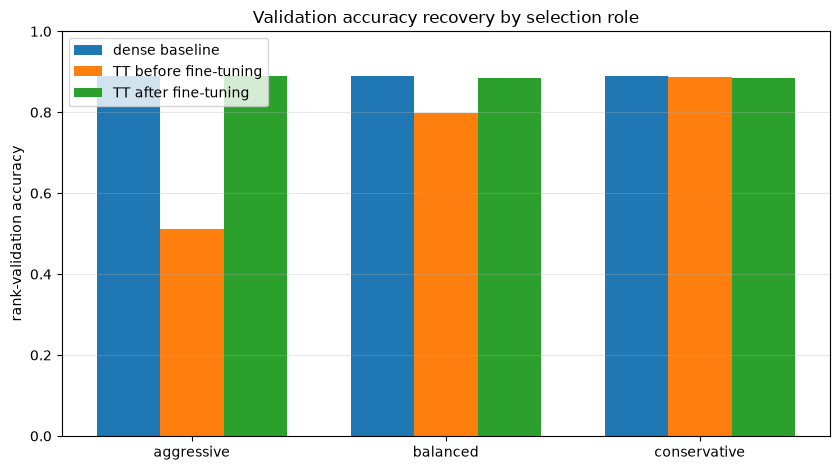

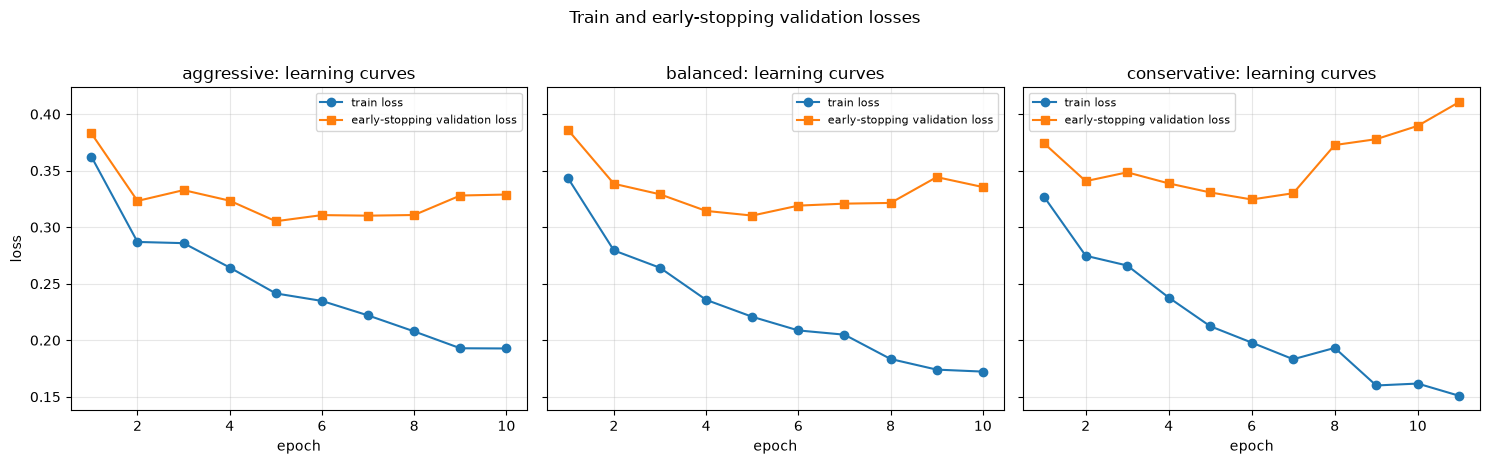

In [23]:
# accuracy図とloss曲線は異なる量を示す。loss側はearly-stopping用のデータで測っている。
# dense baselineの線はaccuracyの比較基準。agreementやRMSEと同じ尺度ではない。

# TODO 3: matplotlibで2つのFigureを作る。
#
# fig_accuracy_recovery:
#   roleごとにdense / before fine-tuning / after fine-tuningを比較する。
# fig_learning_curves:
#   roleごとにtrain loss / early-stopping validation lossを描く。
#
# タイトル、軸ラベル、legend、gridを付ける。

roles = ["aggressive", "balanced", "conservative"]
x = range(len(roles))
width = 0.25

baseline_accs = [baseline_validation_accuracy] * len(roles)
before_accs = [
    float(
        df_finetuning_comparison.loc[
            df_finetuning_comparison["selection_role"] == role,
            "validation_accuracy_before",
        ].iloc[0]
    )
    for role in roles
]
after_accs = [
    float(
        df_finetuning_comparison.loc[
            df_finetuning_comparison["selection_role"] == role,
            "validation_accuracy_after",
        ].iloc[0]
    )
    for role in roles
]

fig_accuracy_recovery, ax_acc = plt.subplots(figsize=(8.5, 4.8))
ax_acc.bar(
    [position - width for position in x],
    baseline_accs,
    width=width,
    label="dense baseline",
)
ax_acc.bar(
    list(x),
    before_accs,
    width=width,
    label="TT before fine-tuning",
)
ax_acc.bar(
    [position + width for position in x],
    after_accs,
    width=width,
    label="TT after fine-tuning",
)
ax_acc.set_xticks(list(x), roles)
ax_acc.set_ylim(0.0, 1.0)
ax_acc.set_ylabel("rank-validation accuracy")
ax_acc.set_title("Validation accuracy recovery by selection role")
ax_acc.grid(True, axis="y", alpha=0.3)
ax_acc.legend()
fig_accuracy_recovery.tight_layout()
plt.show()

fig_learning_curves, axes_lc = plt.subplots(
    1, len(roles), figsize=(15, 4.5), sharey=True
)
for ax, role in zip(axes_lc, roles):
    history = df_finetuning_history.loc[
        df_finetuning_history["selection_role"] == role
    ].sort_values("epoch")
    ax.plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label="train loss",
    )
    ax.plot(
        history["epoch"],
        history["validation_loss"],
        marker="s",
        label="early-stopping validation loss",
    )
    ax.set_xlabel("epoch")
    ax.set_title(f"{role}: learning curves")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes_lc[0].set_ylabel("loss")
fig_learning_curves.suptitle(
    "Train and early-stopping validation losses",
    y=1.02,
)
fig_learning_curves.tight_layout()
plt.show()


## 9. TODO 4：結果とcheckpointを保存する

`SAVE_RESULTS=True`のときだけ、次を保存します。

結果：

- `finetuning_comparison.csv`
- `finetuning_history.csv`
- `finetuning_accuracy_recovery.png`
- `finetuning_learning_curves.png`

checkpoint：

- `aggressive_finetuned.pt`
- `balanced_finetuned.pt`
- `conservative_finetuned.pt`

tuple列はCSVへ保存するコピー上だけ文字列化します。in-memoryのDataFrameは変更しません。保存前に`results_dir`と`models_dir`を作成してください。

In [24]:
# best状態へ復元済みのモデルを保存する。最終epochの状態とbestは一致するとは限らない。
# state_dictを読む側では、同じmodes・rankのモデル構造を先に作る必要がある。

# TODO 4: SAVE_RESULTSがTrueのときだけCSV、Figure、3 checkpointを保存する。
#
# results_dir / models_dir は、このセルでmkdir(parents=True, exist_ok=True)する。
# checkpointには各候補のbest stateへ戻済みmodel.state_dict()を保存する。
# test結果や最終判定の文章分析は、ここでは行わない。

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    # 抽出した表を独立に編集し、元の比較表を変更しない。
    comparison_to_save = df_finetuning_comparison.copy()
    # 抽出した表を独立に編集し、元の比較表を変更しない。
    history_to_save = df_finetuning_history.copy()
    for column in ["out_modes", "in_modes", "actual_ranks"]:
        comparison_to_save[column] = comparison_to_save[column].map(str)

    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    comparison_to_save.to_csv(
        results_dir / "finetuning_comparison.csv",
        index=False,
    )
    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    history_to_save.to_csv(
        results_dir / "finetuning_history.csv",
        index=False,
    )
    # 作成済みのFigureを保存する。図は入力表に記録された結果を示す。
    fig_accuracy_recovery.savefig(
        results_dir / "finetuning_accuracy_recovery.png",
        dpi=150,
        bbox_inches="tight",
    )
    # 作成済みのFigureを保存する。図は入力表に記録された結果を示す。
    fig_learning_curves.savefig(
        results_dir / "finetuning_learning_curves.png",
        dpi=150,
        bbox_inches="tight",
    )

    for record in fine_tuning_records:
        role = record["selection_role"]
        checkpoint_file = models_dir / f"{role}_finetuned.pt"
        # 選択済みparameterを保存する。モデル構造・optimizer・乱数の全情報を含むとは限らない。
        torch.save(record["model"].state_dict(), checkpoint_file)
        print("saved checkpoint:", checkpoint_file)

    print("saved tables/figures to:", results_dir)
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")


saved checkpoint: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning\aggressive_finetuned.pt
saved checkpoint: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning\balanced_finetuned.pt
saved checkpoint: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning\conservative_finetuned.pt
saved tables/figures to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning


## 10. 実装後の検証チェックリスト

Restart Kernel → Run Allの後、次を確認します。

- 09から3候補だけを読み込んだ
- 各候補を新しい`MNISTMLP`と同じbaseline checkpointから再生成した
- 3候補で同じshuffle順を使った
- optimizerは候補ごとに新規作成し、全model parameterを対象にした
- early stoppingには5,000件の専用validationだけを使った
- before／after比較には別の5,000件のrank-selection validationだけを使った
- fine-tuning前後でparameter数が変わっていない
- dense baselineが変更されていない
- test loaderを評価に使っていない
- 2つのCSV、2つの図、3つのcheckpointが保存された

In [25]:
# TODO: TODO 1〜4の実装後に、上のチェックリストをassertで確認する。
# 重い再学習を繰り返す前に、1候補・少ないepochで方針を確認してもよい。
# 本番では3候補すべてを同一条件で最後まで実行する。

assert len(df_selected) == 3
assert set(df_selected["selection_role"]) == {
    "aggressive", "balanced", "conservative"
}
assert len(fine_tuning_records) == 3
assert len(df_finetuning_comparison) == 3
assert df_finetuning_history["selection_role"].nunique() == 3

# 各候補は独立に同じbaselineから再構成されている
assert isinstance(baseline_model.fc1, torch.nn.Linear)
# 初期値と現在値の完全一致を判定する。指標の近似一致とは別の検証。
assert torch.equal(
    baseline_model.fc1.weight,
    baseline_state["fc1.weight"].to(device=DEVICE, dtype=DTYPE),
)

assert (
    df_finetuning_comparison["model_parameters_before"]
    == df_finetuning_comparison["model_parameters_after"]
).all()

assert df_finetuning_comparison["validation_accuracy_before"].between(0.0, 1.0).all()
assert df_finetuning_comparison["validation_accuracy_after"].between(0.0, 1.0).all()
assert df_finetuning_comparison["prediction_agreement_before"].between(0.0, 1.0).all()
assert df_finetuning_comparison["prediction_agreement_after"].between(0.0, 1.0).all()
assert (df_finetuning_comparison["logits_rmse_before"] >= 0.0).all()
assert (df_finetuning_comparison["logits_rmse_after"] >= 0.0).all()

# test loader は評価に使っていない（変数は予約のまま）
assert "test_loader" in loaders
assert test_dataset_unused is not None

if SAVE_RESULTS:
    expected_csvs = [
        results_dir / "finetuning_comparison.csv",
        results_dir / "finetuning_history.csv",
    ]
    expected_figs = [
        results_dir / "finetuning_accuracy_recovery.png",
        results_dir / "finetuning_learning_curves.png",
    ]
    expected_ckpts = [
        models_dir / "aggressive_finetuned.pt",
        models_dir / "balanced_finetuned.pt",
        models_dir / "conservative_finetuned.pt",
    ]
    for path_item in [*expected_csvs, *expected_figs, *expected_ckpts]:
        assert path_item.is_file(), path_item

print("verification checklist: OK")


verification checklist: OK


## 11. 次への接続

このNotebookの終了地点は、

$$
\text{09で選んだ3候補}
\rightarrow
\text{TT置換直後}
\rightarrow
\text{通常fine-tuning後}
$$

を同一条件で比較するところまでです。

11では10のvalidation結果について、fine-tuning前後のPareto frontierを比較し、rank 24 / 48の追加実験が必要かを判断します。11ではtest setを評価しません。追加実験が不要と判断できた場合は、12でvalidation結果に基づいて最終rankを固定し、その後にtest setを1回だけ評価します。test結果を見て候補やhyperparameterを選び直してはいけません。